# Server CPU Temperature Prediction
Concise, code-only pipeline implementing regression modeling for server thermal telemetry.

### 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error

warnings.filterwarnings('ignore')
print('Libraries imported.')

Libraries imported.


### 2. Load Dataset & Preview

In [2]:
import os
data_path = 'server_cpu_dataset_nonlinear_6000_v2.csv'
if not os.path.exists(data_path):
    data_path = os.path.join('..', 'data', 'server_cpu_dataset_nonlinear_6000_v2.csv')
df = pd.read_csv(data_path)
print('Dataset shape:', df.shape)
df.info()
df.head()

Dataset shape: (6000, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   CPU_Utilization      6000 non-null   float64
 1   Memory_Usage         6000 non-null   float64
 2   Clock_Speed          6000 non-null   float64
 3   Ambient_Temperature  6000 non-null   float64
 4   Voltage              6000 non-null   float64
 5   Current              6000 non-null   float64
 6   Temperature          6000 non-null   float64
dtypes: float64(7)
memory usage: 328.2 KB


,CPU_Utilization,Memory_Usage,Clock_Speed,Ambient_Temperature,Voltage,Current,Temperature
0,43.708611,68.619272,3.135766,31.142267,1.311317,27.335060,48.884519
1,95.564288,32.928977,1.700081,25.060462,1.180543,21.075236,199.621192
2,75.879455,85.429592,2.105825,26.797728,0.933424,38.757448,75.422216
3,63.879264,65.983718,3.434198,32.918120,1.451106,12.664246,67.299422
4,24.041678,31.790291,2.821715,36.907651,1.488197,25.574975,84.248828


### 3. Exploratory Data Analysis

In [3]:
print('Summary Statistics:')
display(df.describe())
print('Missing Values:', df.isnull().sum().sum())

Summary Statistics:


,CPU_Utilization,Memory_Usage,Clock_Speed,Ambient_Temperature,Voltage,Current,Temperature
count,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,54.739367,57.123930,2.753439,27.802433,1.195402,22.456989,86.010517
std,26.058340,21.524845,0.721578,7.225691,0.171047,10.116199,60.266318
min,10.001047,20.003962,1.500631,15.001203,0.900066,5.000194,14.726715
25%,32.115480,38.667010,2.129189,21.649262,1.048287,13.579843,41.797943
50%,54.846492,56.822900,2.759868,27.859678,1.196018,22.540877,59.663051
75%,77.270594,75.754273,3.383048,34.024550,1.339033,31.120311,118.901489
max,99.974591,94.975490,3.999812,39.997524,1.499839,39.992628,331.514212


Missing Values: 0


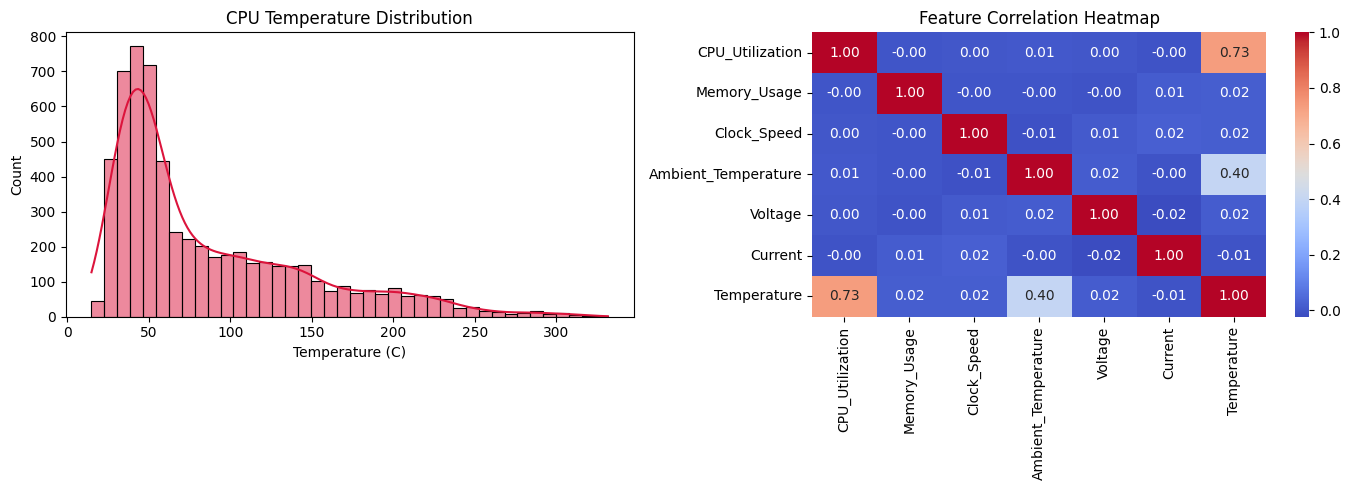

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['Temperature'], bins=40, kde=True, ax=axes[0], color='crimson')
axes[0].set_title('CPU Temperature Distribution')
axes[0].set_xlabel('Temperature (C)')

sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1])
axes[1].set_title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

### 4. Feature Engineering & IQR Outlier Filtering

In [5]:
# Missing value imputation
df.fillna(df.mean(numeric_only=True), inplace=True)

# Feature engineering
df['Power_Load'] = df['Voltage'] * df['Current']
df['Workload'] = df['CPU_Utilization'] * df['Memory_Usage']

features = [
    'CPU_Utilization', 'Memory_Usage', 'Clock_Speed',
    'Ambient_Temperature', 'Voltage', 'Current',
    'Power_Load', 'Workload'
]
target = 'Temperature'

# IQR outlier filtering
for col in features:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    df = df[(df[col] >= q1 - 1.5 * iqr) & (df[col] <= q3 + 1.5 * iqr)]

X = df[features]
y = df[target]
print('Processed dataset shape:', X.shape)

Processed dataset shape: (5958, 8)


### 5. Train-Test Split & Feature Scaling

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

print(f'Train: {X_train_sc.shape[0]} | Test: {X_test_sc.shape[0]}')

Train: 4170 | Test: 1788


### 6. Model Training & 5-Fold Cross-Validation

In [7]:
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree (Shallow)': DecisionTreeRegressor(
        max_depth=2, min_samples_split=80, min_samples_leaf=40, random_state=42
    ),
    'Random Forest': RandomForestRegressor(
        n_estimators=300, max_depth=8, min_samples_split=8, min_samples_leaf=4, max_features='sqrt', random_state=42
    )
}

for name, model in models.items():
    model.fit(X_train_sc, y_train)
    cv_scores = cross_val_score(model, X_train_sc, y_train, cv=5, scoring='r2')
    print(f'{name:<24} -> 5-Fold CV R2: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})')

Linear Regression        -> 5-Fold CV R2: 0.6918 (+/- 0.0183)


Decision Tree (Shallow)  -> 5-Fold CV R2: 0.8368 (+/- 0.0057)


Random Forest            -> 5-Fold CV R2: 0.9608 (+/- 0.0030)


### 7. Benchmark & Evaluation Metrics

In [8]:
results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test_sc)
    predictions[name] = y_pred
    
    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100
    
    results.append({
        'Model': name,
        'Test R2': round(r2, 4),
        'RMSE (C)': round(rmse, 2),
        'MSE': round(mse, 2),
        'MAPE (%)': round(mape, 2)
    })

eval_df = pd.DataFrame(results)
display(eval_df)

,Model,Test R2,RMSE (C),MSE,MAPE (%)
0,Linear Regression,0.6824,33.71,1136.29,38.25
1,Decision Tree (Shallow),0.8335,24.40,595.58,25.84
2,Random Forest,0.9633,11.46,131.26,11.62


### 8. Actual vs. Predicted & Residuals

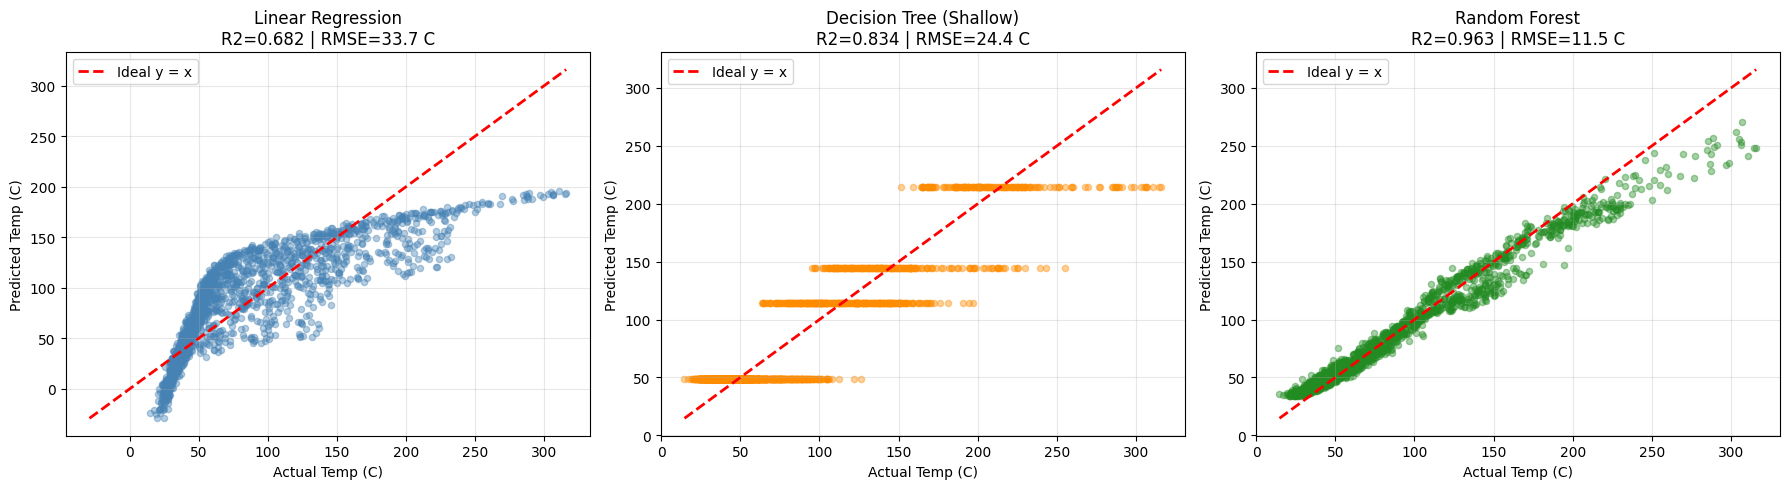

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ['steelblue', 'darkorange', 'forestgreen']

for idx, (name, preds) in enumerate(predictions.items()):
    ax = axes[idx]
    ax.scatter(y_test, preds, alpha=0.4, color=colors[idx], s=20)
    lims = [min(y_test.min(), preds.min()), max(y_test.max(), preds.max())]
    ax.plot(lims, lims, 'r--', lw=2, label='Ideal y = x')
    ax.set_title(f'{name}\nR2={r2_score(y_test, preds):.3f} | RMSE={np.sqrt(mean_squared_error(y_test, preds)):.1f} C')
    ax.set_xlabel('Actual Temp (C)')
    ax.set_ylabel('Predicted Temp (C)')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

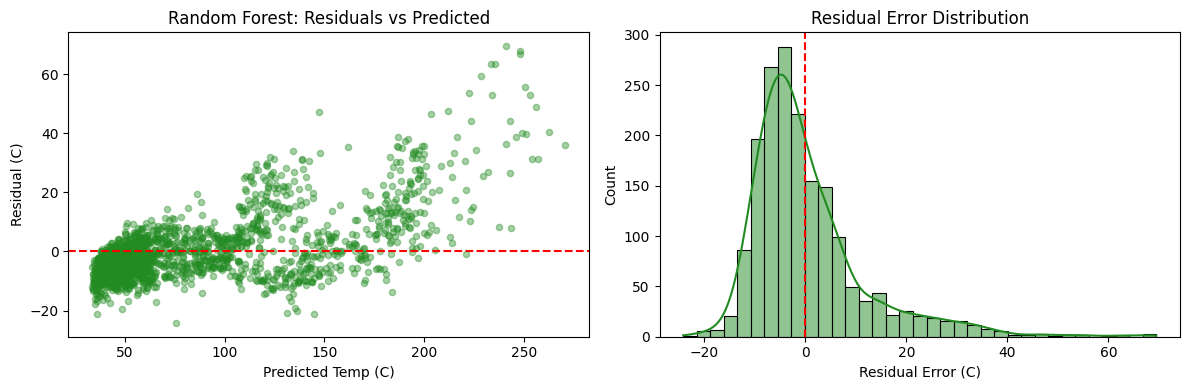

In [10]:
rf_residuals = y_test - predictions['Random Forest']

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.scatter(predictions['Random Forest'], rf_residuals, alpha=0.4, color='forestgreen', s=20)
plt.axhline(0, color='red', linestyle='--')
plt.title('Random Forest: Residuals vs Predicted')
plt.xlabel('Predicted Temp (C)')
plt.ylabel('Residual (C)')

plt.subplot(1, 2, 2)
sns.histplot(rf_residuals, bins=35, kde=True, color='forestgreen')
plt.axvline(0, color='red', linestyle='--')
plt.title('Residual Error Distribution')
plt.xlabel('Residual Error (C)')
plt.tight_layout()
plt.show()

### 9. Feature Importance (Random Forest)

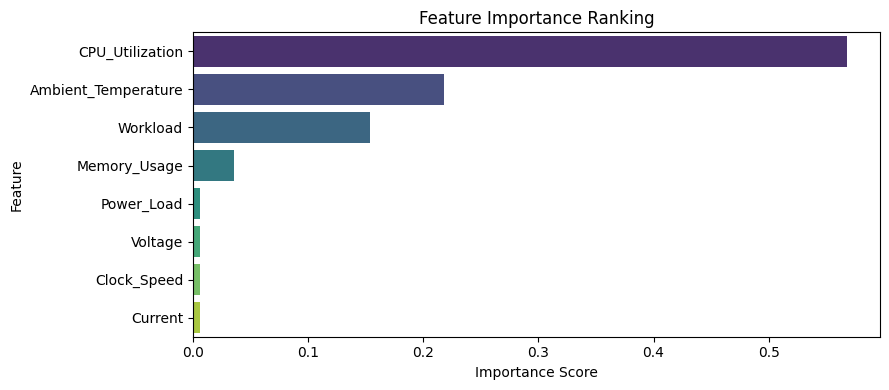

,Feature,Importance
0,CPU_Utilization,0.568256
3,Ambient_Temperature,0.218459
7,Workload,0.153812
1,Memory_Usage,0.035545
6,Power_Load,0.006126
4,Voltage,0.006126
2,Clock_Speed,0.005889
5,Current,0.005787


In [11]:
rf_model = models['Random Forest']
imp_df = pd.DataFrame({
    'Feature': features,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(9, 4))
sns.barplot(data=imp_df, x='Importance', y='Feature', palette='viridis')
plt.title('Feature Importance Ranking')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

display(imp_df)

### 10. Model Serialization

In [12]:
joblib.dump(models['Random Forest'], 'rf_model.pkl')
joblib.dump(models['Decision Tree (Shallow)'], 'dt_model.pkl')
joblib.dump(models['Linear Regression'], 'lr_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
print('Models and scaler saved successfully.')

Models and scaler saved successfully.


### 11. Inference Function

In [13]:
def predict_cpu_temperature(cpu_util, mem_usage, clock_spd, amb_temp, volt, curr, model_name='Random Forest'):
    power_load = volt * curr
    workload = cpu_util * mem_usage
    
    input_df = pd.DataFrame([[cpu_util, mem_usage, clock_spd, amb_temp, volt, curr, power_load, workload]], columns=features)
    input_sc = scaler.transform(input_df)
    
    pred = models[model_name].predict(input_sc)[0]
    status = 'NORMAL (< 60C)' if pred < 60 else ('WARNING (60C - 80C)' if pred < 80 else 'CRITICAL (> 80C)')
    return round(pred, 2), status

# Sample prediction test
temp, status = predict_cpu_temperature(cpu_util=75, mem_usage=60, clock_spd=3.0, amb_temp=28, volt=1.2, curr=25)
print(f'Predicted CPU Temperature: {temp} C | Thermal Alert: {status}')

Predicted CPU Temperature: 74.85 C | Thermal Alert: WARNING (60C - 80C)
